**Setup python**

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import scienceplots

plt.style.use(['science'])


**Load MNIST data**

In [2]:
# Load the data from MNIST-5-6-Subset.txt
data_file_path = "data\\MNIST-5-6-Subset.txt"
data_matrix = np.loadtxt(data_file_path).reshape(1877, 784)

# Load the labels from MNIST-5-6-Labels.txt
labels_file_path = "data\\MNIST-5-6-Subset-Labels.txt"
labels = np.loadtxt(labels_file_path)

**Visualize the first image**

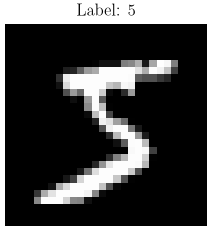

In [3]:
# Index of the image you want to visualize
image_index = 0  
image_data = data_matrix[image_index]
selected_label = int(labels[image_index])

# Visualize the image using Matplotlib
plt.imshow(image_data.reshape(28,28).transpose(1,0), cmap='gray') # We transpose the image to make the number look upright.
plt.title(f"Label: {selected_label}")
plt.axis('off') # Turn off axis
plt.show()

**K-NN python function**

In [4]:
# Create training points and labels
def training(m):
    training_point = data_matrix[:m, :]
    training_label = labels[:m]
    return training_point, training_label


# Create validation sets
def validation_sets(m, num_val_sets, n):
    validation_sets = []
    for i in range(1, num_val_sets+1):
        validation_point = data_matrix[m + (i-1)*n : m + i*n, :]
        validation_label = labels[m + (i-1)*n : m + i*n]
        validation_sets.append([validation_point, validation_label])
    return validation_sets


# Create KNN function
def knn(training_point, training_labels, test_points, test_labels):

    # squared Euclidean distance #(m,n)
    E_dist = (
        np.sum(training_point**2, axis=1)[:, None] - #(m,d)
        2 * training_point @ test_points.T + #(m,d) @ (n,d)^T = (m,n)
        np.sum(test_points**2, axis=1)[None, :] #(n,d)
    )

    # Convert labels: 5 -> -1, 6 -> 1
    training_labels = np.where(training_labels == 5, -1, 1)

    # Sort indexes by Euclidean distance 
    nearest_index = np.argsort(E_dist, axis=0)

    # Cumulative sum of the sorted predicted labels
    knn_cumsum = np.cumsum(training_labels[nearest_index], axis=0)

    # Majority vote: if the sum is positive, predict 1 (label 6), else predict -1 (label 5)
    knn_pred = np.where(knn_cumsum > 0, 6, 5)

    # Calculate errors
    error_raw = np.mean(knn_pred != test_labels[None,:],axis=1)

    # Create an array to store the predicted labels for each test point
    k_vals = np.arange(1, len(training_labels)+1)
    error = np.column_stack([k_vals, error_raw])

    
    return error

**Create figures with validation errors** 

In [8]:

m = 50 # number of training points
num_val_sets = 5 # number of validation sets
num_test_points = [10, 20, 40, 80] # number of test points in each of the 5 validation sets

for test_points in num_test_points:
    # create training points and labels
    training_point, training_label = training(m)

    # create validation sets  
    val_sets = validation_sets(m, num_val_sets, test_points)

    # Calculate validation errors for each validation set
    val_errors = []
    for i in val_sets:
        error = knn(training_point, training_label, i[0], i[1])
        val_errors.append(error)

    plt.figure(figsize=(10, 6))

    for j, errors in enumerate(val_errors):
        plt.plot(errors[:, 0], errors[:, 1], label=f"Validation set {j + 1}")

    plt.xlabel("K (number of nearest neighbors)")
    plt.ylabel("Validation error")
    plt.title(f"K-NN Validation Error ({test_points} test points)")
    plt.legend()
    plt.grid(True)

    output_dir = "output/"
    filename = f"K-NN_Validation_Error_{test_points}.png"
    plt.savefig(output_dir + filename, dpi=300, bbox_inches="tight")
    plt.close()



**Create validation error variance figure**

In [ ]:

m = 50 # number of training points
num_val_sets = 5 # number of validation sets
num_test_points = [10, 20, 40, 80] # number of test points in each of the 5 validation sets



var_errors = []  # List to store variance of validation errors for each test point size

for test_points in num_test_points:
    # create training points and labels
    training_point, training_label = training(m)

    # create validation sets  
    val_sets = validation_sets(m, num_val_sets, test_points)

    # Calculate validation errors for each validation set
    val_errors = []
    for i in val_sets:
        error = knn(training_point, training_label, i[0], i[1])
        val_errors.append(error)

    val_errors = np.array(val_errors)

    variance = np.var(val_errors[:,:, 1], axis=0)

    var_errors.append(variance)

var_errors

k_vals = np.arange(1, m+1)

plt.figure(figsize=(10, 6))

for test_points, variance in zip(num_test_points, var_errors):
    plt.plot(
        k_vals,
        variance,
        label=f"{test_points} test points"
    )

plt.xlabel("K (number of nearest neighbors)")
plt.ylabel("Validation error variance")
plt.title("K-NN Validation Error variance")
plt.legend(loc="upper left")
plt.grid(True)

output_dir = "output/"
filename = "K-NN_Validation_Error_variance.png"
plt.savefig(output_dir + filename, dpi=300, bbox_inches="tight")
plt.close()